## Import Required Libraries

In [1]:
# ============================================
# 1. IMPORT LIBRARIES
# ============================================

import numpy as np
import pandas as pd

import random
import math
import time
import os

import matplotlib.pyplot as plt

import pulp

## Generate Synthetic Dataset

In [2]:
# ============================================
# 2. SYNTHETIC DATASET GENERATION
# ============================================

np.random.seed(42)

n_customers = 20

customers = pd.DataFrame({
    "customer_id": range(1, n_customers + 1),
    "x": np.random.uniform(0, 100, n_customers),
    "y": np.random.uniform(0, 100, n_customers),
    "demand": np.random.randint(1, 10, n_customers)
})

# Depot
depot = {
    "customer_id": 0,
    "x": 50,
    "y": 50,
    "demand": 0
}

print("Synthetic Dataset")
print("=================")
print(customers)

print("\nDepot:")
print(depot)

Synthetic Dataset
    customer_id          x          y  demand
0             1  37.454012  61.185289       7
1             2  95.071431  13.949386       8
2             3  73.199394  29.214465       3
3             4  59.865848  36.636184       1
4             5  15.601864  45.606998       4
5             6  15.599452  78.517596       2
6             7   5.808361  19.967378       8
7             8  86.617615  51.423444       4
8             9  60.111501  59.241457       2
9            10  70.807258   4.645041       6
10           11   2.058449  60.754485       6
11           12  96.990985  17.052412       4
12           13  83.244264   6.505159       6
13           14  21.233911  94.888554       2
14           15  18.182497  96.563203       2
15           16  18.340451  80.839735       4
16           17  30.424224  30.461377       8
17           18  52.475643   9.767211       7
18           19  43.194502  68.423303       9
19           20  29.122914  44.015249       8

Depot:
{'custom

## Dataset Justification

The dataset is synthetic, generated to represent a small delivery company that serves customers from a single warehouse.

| Element | Value | Real-world meaning |
|---|---|---|
| Service area | 0–100 on each axis | A 100 km × 100 km region around a city |
| Depot | (50, 50) | Central warehouse where every vehicle starts and ends its route |
| Customers | 20, placed uniformly at random | Delivery addresses spread across the region |
| Demand | 1–9 units per customer | Parcels or crates per delivery |
| Fleet | 4 vehicles, capacity 30 each | Small courier vans |

**Realism.** Total demand is 101 units against a total fleet capacity of 120 units (84% utilisation). The fleet can serve every customer, but only with little spare room, so the capacity constraint actively shapes the routes, as it does in real delivery planning. Distances are Euclidean, a standard approximation of road distance in vehicle routing studies.

**Why synthetic data.** The same generator can create instances of any size, which is needed for the scalability experiment (10 to 100 customers). The problem size can then be changed while everything else stays the same.

**Reproducibility.** A fixed random seed (42) means anyone running the notebook obtains exactly the same customers, demands and results.

## Dataset Generation Function

In [3]:
# ============================================
# 3. DATASET GENERATION FUNCTION
# ============================================

def generate_dataset(n_customers, seed=42):

    np.random.seed(seed)

    data = pd.DataFrame({
        "customer_id": range(1, n_customers + 1),
        "x": np.random.uniform(0, 100, n_customers),
        "y": np.random.uniform(0, 100, n_customers),
        "demand": np.random.randint(1, 10, n_customers)
    })

    return data


# Generate default dataset
customers = generate_dataset(20, seed=42)

customers.head()

,customer_id,x,y,demand
0,1,37.454012,61.185289,7
1,2,95.071431,13.949386,8
2,3,73.199394,29.214465,3
3,4,59.865848,36.636184,1
4,5,15.601864,45.606998,4


## Vehicle Configuration

In [4]:
# ============================================
# 4. VEHICLE CONFIGURATION
# ============================================

NUM_VEHICLES = 4
VEHICLE_CAPACITY = 30

print("Number of vehicles:", NUM_VEHICLES)
print("Vehicle capacity:", VEHICLE_CAPACITY)

Number of vehicles: 4
Vehicle capacity: 30


## Feasibility Check

In [5]:
# ============================================
# 5. FEASIBILITY CHECK
# ============================================

total_demand = customers["demand"].sum()
total_capacity = NUM_VEHICLES * VEHICLE_CAPACITY

print("Total demand:", total_demand)
print("Total vehicle capacity:", total_capacity)

if total_demand <= total_capacity:
    print("Problem is feasible.")
else:
    print("Problem is infeasible.")

Total demand: 101
Total vehicle capacity: 120
Problem is feasible.


## Distance Matrix

In [6]:
# ============================================
# 6. DISTANCE MATRIX
# ============================================

def calculate_distance_matrix(
    customers,
    depot_x=50,
    depot_y=50,
    rounded=False
):
    
    locations = [
        (depot_x, depot_y)
    ] + list(
        zip(customers["x"], customers["y"])
    )

    n = len(locations)

    distance_matrix = np.zeros((n, n))

    for i in range(n):
        for j in range(n):

            x1, y1 = locations[i]
            x2, y2 = locations[j]

            distance = np.sqrt(
                (x1 - x2) ** 2 +
                (y1 - y2) ** 2
            )

            if rounded:
                distance = int(distance + 0.5)

            distance_matrix[i][j] = distance

    return distance_matrix


distance_matrix = calculate_distance_matrix(
    customers
)

print("Distance matrix shape:", distance_matrix.shape)

Distance matrix shape: (21, 21)


## Why Integer Linear Programming (ILP)?

**ILP provides an exact optimization approach.** Unlike the Genetic Algorithm, which searches for a high-quality solution without guaranteeing optimality, ILP can provide a mathematically optimal solution when the solver reaches proven optimality. This makes ILP useful as a benchmark for evaluating the heuristic method.

**The CVRP can be formulated as a binary integer optimization problem.** Binary decision variables indicate whether a vehicle travels directly from one node to another. The objective is to minimize the total travel distance while satisfying customer, depot, vehicle capacity, and route constraints.

**Why ILP fits this problem:**
- **Exact optimization.** For instances that can be solved to optimality, the ILP provides a guaranteed optimal solution.
- **Clear mathematical formulation.** The routing decisions and constraints can be represented explicitly using binary and continuous variables.
- **Capacity constraints.** Vehicle capacity can be incorporated directly into the mathematical model.
- **Subtour elimination.** MTZ constraints prevent disconnected customer cycles that do not include the depot.
- **Benchmark for the GA.** The ILP solution provides an exact or best-known reference against which the Genetic Algorithm can be compared.
- **Feasibility guarantees.** The solver searches only for solutions satisfying the specified mathematical constraints.

**Trade-off.** The main limitation of ILP is computational scalability. CVRP is NP-hard, so the number of possible routing combinations grows rapidly as the number of customers increases. For larger instances, the solver may require substantially more time and may terminate before proving optimality. Therefore, a time limit is used for larger instances, and the resulting solution is reported together with its optimality status or solver gap.

## ILP Formulation

Let:

- $V = \{0,1,\dots,n\}$ be the set of nodes, where node $0$ is the depot.
- $C = V \setminus \{0\}$ be the set of customers.
- $K$ be the maximum number of available vehicles.
- $Q$ be the capacity of each vehicle.
- $q_i$ be the demand of customer $i$.
- $d_{ij}$ be the distance from node $i$ to node $j$.

### Decision Variables

The main binary decision variable is:

$$
x_{ij} =
\begin{cases}
1, & \text{if a route travels directly from node } i \text{ to node } j\\
0, & \text{otherwise}
\end{cases}
$$

A continuous load variable $u_i$ is also used to support the capacity and subtour-elimination constraints.

### Objective Function

The objective is to minimize the total travel distance of all vehicles:

$$
\min
\sum_{i \in V}
\sum_{\substack{j \in V\\j \neq i}}
d_{ij}x_{ij}
$$

where $d_{ij}$ represents the Euclidean distance between nodes $i$ and $j$.

### Constraints

**1. Each customer is visited exactly once**

Each customer must have exactly one incoming route:

$$
\sum_{\substack{i \in V\\i \neq j}} x_{ij} = 1
\qquad \forall j \in C
$$

Each customer must also have exactly one outgoing route:

$$
\sum_{\substack{j \in V\\j \neq i}} x_{ij} = 1
\qquad \forall i \in C
$$

**2. Vehicle limit**

At most $K$ vehicles can leave the depot:

$$
\sum_{j \in C} x_{0j} \leq K
$$

The same number of routes must return to the depot:

$$
\sum_{i \in C} x_{i0} \leq K
$$

**3. Vehicle capacity**

The total demand assigned to each route cannot exceed the vehicle capacity $Q$.

The load variables satisfy:

$$
q_i \leq u_i \leq Q
\qquad \forall i \in C
$$

and the capacity relationship is enforced using:

$$
u_i - u_j + Qx_{ij} \leq Q-q_j
\qquad \forall i,j \in C,\; i\neq j
$$

This prevents a vehicle route from carrying more demand than its available capacity.

**4. Subtour elimination**

The load-based constraints also prevent disconnected subtours between customers. For example, an invalid solution such as:

$$
2 \rightarrow 5 \rightarrow 7 \rightarrow 2
$$

without connecting to the depot is eliminated by the MTZ/load constraints.

Therefore, every customer route must ultimately be connected to the depot.

**5. Binary decision variables**

$$
x_{ij} \in \{0,1\}
\qquad \forall i,j \in V,\; i\neq j
$$

and:

$$
x_{ii}=0
$$

A node cannot travel directly to itself.

## ILP Constraint Summary

| Constraint | How the ILP enforces it |
|---|---|
| Each customer visited exactly once | One incoming and one outgoing arc for every customer |
| Vehicle capacity $Q$ | Load variables and capacity constraints |
| Maximum $K$ vehicles | Limits the number of routes leaving and returning to the depot |
| Routes start and end at depot | Depot flow constraints |
| No disconnected subtours | MTZ/load-based subtour elimination constraints |
| Valid routing decisions | Binary variables $x_{ij}$ |

## ILP Solver Configuration

The model is implemented using **PuLP** and solved using the CBC mixed-integer programming solver.

For each problem instance, the following information is recorded:

- Total route distance
- Number of vehicles/routes used
- Solver runtime
- Solver status
- Optimality gap, when available
- Feasibility of the final solution

For small instances, the solver is allowed to continue until optimality is proven. For larger instances, a predefined time limit is used to study the scalability of the exact method.

The resulting ILP solution is then compared with the Genetic Algorithm solution using the same dataset, objective function, and feasibility requirements.

## ILP Solver

In [7]:
# ============================================
# 7. ILP SOLVER
# ============================================

def solve_ilp(
    customers,
    distance_matrix,
    num_vehicles,
    vehicle_capacity,
    time_limit=300
):
    n = len(customers)

    nodes = range(n + 1)
    customer_nodes = range(1, n + 1)

    demands = {
        i: int(customers.iloc[i - 1]["demand"])
        for i in customer_nodes
    }

    model = pulp.LpProblem("CVRP_ILP", pulp.LpMinimize)

    x = pulp.LpVariable.dicts(
        "x",
        [
            (i, j)
            for i in nodes
            for j in nodes
            if i != j
        ],
        cat="Binary"
    )

    u = pulp.LpVariable.dicts(
        "u",
        customer_nodes,
        lowBound=0,
        upBound=vehicle_capacity,
        cat="Continuous"
    )

    # Objective
    model += pulp.lpSum(
        distance_matrix[i, j] * x[i, j]
        for i in nodes
        for j in nodes
        if i != j
    )

    # Every customer has exactly one incoming arc.
    for j in customer_nodes:
        model += pulp.lpSum(
            x[i, j]
            for i in nodes
            if i != j
        ) == 1

    # Every customer has exactly one outgoing arc.
    for i in customer_nodes:
        model += pulp.lpSum(
            x[i, j]
            for j in nodes
            if i != j
        ) == 1

    # At most K vehicles leave the depot.
    model += pulp.lpSum(
        x[0, j] for j in customer_nodes
    ) <= num_vehicles

    # Number of vehicles leaving = number returning.
    model += (
        pulp.lpSum(x[0, j] for j in customer_nodes)
        ==
        pulp.lpSum(x[i, 0] for i in customer_nodes)
    )

    # Load bounds.
    for i in customer_nodes:
        model += u[i] >= demands[i]
        model += u[i] <= vehicle_capacity

    # MTZ/load constraints.
    for i in customer_nodes:
        for j in customer_nodes:
            if i != j:
                model += (
                    u[j]
                    >=
                    u[i] + demands[j]
                    - vehicle_capacity * (1 - x[i, j])
                )

    solver = pulp.PULP_CBC_CMD(
        msg=False,
        timeLimit=time_limit
    )

    start = time.perf_counter()
    model.solve(solver)
    runtime = time.perf_counter() - start

    return model, x, u, runtime

## Run ILP

In [10]:
# ============================================
# 8. RUN ILP
# ============================================

model, x, u, ilp_runtime = solve_ilp(
    customers=customers,
    distance_matrix=distance_matrix,
    num_vehicles=NUM_VEHICLES,
    vehicle_capacity=VEHICLE_CAPACITY,
    time_limit=300
)

print("ILP Status:", pulp.LpStatus[model.status])

if model.status in [
    pulp.LpStatusOptimal,
    pulp.LpStatusNotSolved,
    pulp.LpStatusInfeasible,
    pulp.LpStatusUndefined,
    pulp.LpStatusInfeasible
]:
    print("ILP Objective:", pulp.value(model.objective))

print("ILP Runtime:", round(ilp_runtime, 4), "seconds")

ILP Status: Optimal
ILP Objective: 586.4932022289157
ILP Runtime: 299.4067 seconds


## ILP Route Extraction

In [11]:
# ============================================
# 9. EXTRACT ILP ROUTES
# ============================================

def extract_routes(model, x, n):

    routes = []

    for vehicle_start in range(1, n + 1):

        start_value = pulp.value(
            x[0, vehicle_start]
        )

        if start_value is not None and start_value > 0.5:

            route = [0, vehicle_start]

            current = vehicle_start

            while True:

                next_node = None

                for j in range(n + 1):

                    if j != current:

                        value = pulp.value(
                            x[current, j]
                        )

                        if value is not None and value > 0.5:

                            next_node = j
                            break

                if next_node is None:

                    raise ValueError(
                        f"Could not find next node from {current}"
                    )

                route.append(next_node)

                if next_node == 0:
                    break

                current = next_node

            routes.append(route)

    return routes

## Display ILP Routes

In [12]:
# ============================================
# 10. DISPLAY ILP ROUTES
# ============================================

ilp_routes = extract_routes(
    model,
    x,
    len(customers)
)

print("ILP Routes")
print("==========")

for i, route in enumerate(ilp_routes, start=1):

    print(
        f"Vehicle {i}: {route}"
    )

ILP Routes
Vehicle 1: [0, 4, 3, 13, 2, 12, 8, 0]
Vehicle 2: [0, 7, 16, 14, 15, 6, 11, 5, 0]
Vehicle 3: [0, 9, 19, 1, 0]
Vehicle 4: [0, 17, 20, 18, 10, 0]


## Route Distance and Load Functions

In [13]:
# ============================================
# 11. ROUTE CALCULATION FUNCTIONS
# ============================================

def calculate_route_distance(
    route,
    distance_matrix
):

    distance = 0

    for i in range(len(route) - 1):

        distance += distance_matrix[
            route[i]
        ][
            route[i + 1]
        ]

    return distance


def calculate_route_load(
    route,
    customers
):

    load = 0

    for node in route:

        if node != 0:

            load += int(
                customers.iloc[node - 1]["demand"]
            )

    return load


def calculate_total_distance(
    routes,
    distance_matrix
):

    return sum(
        calculate_route_distance(
            route,
            distance_matrix
        )
        for route in routes
    )

## Solution Validation

In [14]:
# ============================================
# 12. SOLUTION VALIDATION
# ============================================

def validate_solution(
    routes,
    customers,
    num_vehicles,
    vehicle_capacity
):

    errors = []

    n_customers = len(customers)

    # ----------------------------------------
    # Vehicle count
    # ----------------------------------------

    if len(routes) > num_vehicles:

        errors.append(
            f"Uses {len(routes)} vehicles, "
            f"maximum allowed is {num_vehicles}"
        )

    # ----------------------------------------
    # Check routes
    # ----------------------------------------

    visited_customers = []

    for vehicle_number, route in enumerate(
        routes,
        start=1
    ):

        # Start/end depot
        if route[0] != 0:

            errors.append(
                f"Vehicle {vehicle_number} "
                f"does not start at depot."
            )

        if route[-1] != 0:

            errors.append(
                f"Vehicle {vehicle_number} "
                f"does not end at depot."
            )

        # Check capacity
        load = calculate_route_load(
            route,
            customers
        )

        if load > vehicle_capacity:

            errors.append(
                f"Vehicle {vehicle_number} "
                f"exceeds capacity: {load}"
            )

        # Collect customers
        for node in route:

            if node != 0:

                visited_customers.append(node)

    # ----------------------------------------
    # Check all customers visited once
    # ----------------------------------------

    expected = set(
        range(1, n_customers + 1)
    )

    visited = set(
        visited_customers
    )

    if visited != expected:

        missing = expected - visited
        extra = visited - expected

        if missing:

            errors.append(
                f"Missing customers: {sorted(missing)}"
            )

        if extra:

            errors.append(
                f"Invalid customers: {sorted(extra)}"
            )

    # Duplicate customers
    if len(visited_customers) != len(
        set(visited_customers)
    ):

        errors.append(
            "Some customers are visited more than once."
        )

    # ----------------------------------------
    # Result
    # ----------------------------------------

    if len(errors) == 0:

        return True, [
            "All customers are visited exactly once.",
            "All routes start and end at the depot.",
            "All vehicle capacities are respected.",
            "Vehicle count is within the allowed limit."
        ]

    return False, errors

## Validate ILP

In [15]:
# ============================================
# 13. VALIDATE ILP
# ============================================

ilp_valid, ilp_messages = validate_solution(
    ilp_routes,
    customers,
    NUM_VEHICLES,
    VEHICLE_CAPACITY
)

print("ILP solution valid:", ilp_valid)

for message in ilp_messages:

    print("-", message)

ILP solution valid: True
- All customers are visited exactly once.
- All routes start and end at the depot.
- All vehicle capacities are respected.
- Vehicle count is within the allowed limit.


## Print ILP Route Details

In [16]:
# ============================================
# 14. ILP ROUTE DETAILS
# ============================================

print("ILP Route Details")
print("=================")

for i, route in enumerate(
    ilp_routes,
    start=1
):

    distance = calculate_route_distance(
        route,
        distance_matrix
    )

    load = calculate_route_load(
        route,
        customers
    )

    print(
        f"Vehicle {i}: "
        f"Route={route}, "
        f"Load={load}, "
        f"Distance={distance:.2f}"
    )

print(
    "\nTotal ILP distance:",
    calculate_total_distance(
        ilp_routes,
        distance_matrix
    )
)

ILP Route Details
Vehicle 1: Route=[0, 4, 3, 13, 2, 12, 8, 0], Load=26, Distance=146.87
Vehicle 2: Route=[0, 7, 16, 14, 15, 6, 11, 5, 0], Load=28, Distance=228.97
Vehicle 3: Route=[0, 9, 19, 1, 0], Load=18, Distance=58.99
Vehicle 4: Route=[0, 17, 20, 18, 10, 0], Load=29, Distance=151.66

Total ILP distance: 586.4932022289157


## ILP Route Map

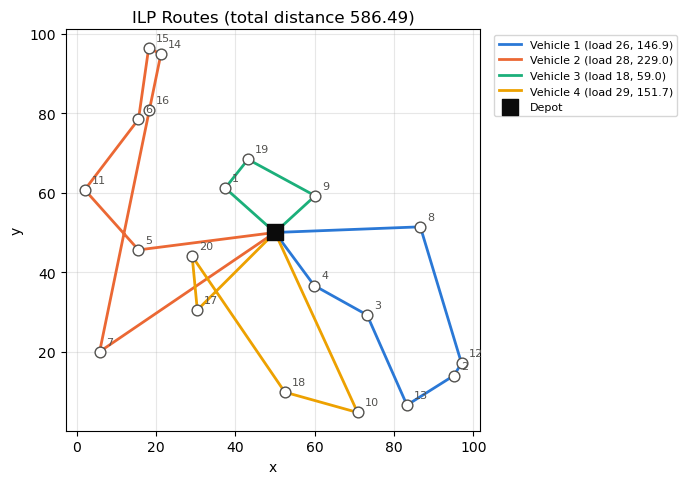

In [17]:
# ============================================
# 15. ILP ROUTE MAP
# ============================================

# Fixed colour order: vehicle k always gets the same colour
ROUTE_COLORS = [
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100",
    "#e87ba4", "#008300", "#4a3aa7", "#e34948"
]


def plot_routes(
    routes,
    customers,
    distance_matrix,
    title,
    depot_x=50,
    depot_y=50,
    ax=None
):

    if ax is None:
        _, ax = plt.subplots(figsize=(7, 7))

    xs = [depot_x] + customers["x"].tolist()
    ys = [depot_y] + customers["y"].tolist()

    for k, route in enumerate(routes):

        load = calculate_route_load(route, customers)
        distance = calculate_route_distance(route, distance_matrix)

        ax.plot(
            [xs[node] for node in route],
            [ys[node] for node in route],
            color=ROUTE_COLORS[k % len(ROUTE_COLORS)],
            linewidth=2,
            label=f"Vehicle {k + 1} (load {load}, {distance:.1f})"
        )

    # Customers
    ax.scatter(
        xs[1:], ys[1:],
        s=60, color="white",
        edgecolor="#52514e", zorder=3
    )

    for node in range(1, len(xs)):

        ax.annotate(
            str(node),
            (xs[node], ys[node]),
            textcoords="offset points",
            xytext=(5, 5),
            fontsize=8,
            color="#52514e"
        )

    # Depot
    ax.scatter(
        [depot_x], [depot_y],
        s=120, marker="s", color="#0b0b0b",
        zorder=4, label="Depot"
    )

    total = calculate_total_distance(routes, distance_matrix)

    ax.set_title(f"{title} (total distance {total:.2f})")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8)

    return ax


plot_routes(
    ilp_routes,
    customers,
    distance_matrix,
    title="ILP Routes"
)

plt.tight_layout()
plt.show()

## Why a Genetic Algorithm?

**The problem is NP-hard.** The CVRP contains the Travelling Salesman Problem as a special case (one vehicle with unlimited capacity), so no known algorithm solves it to proven optimality in polynomial time. With 20 customers there are already $20! \approx 2.4 \times 10^{18}$ possible visiting orders, before they are split into routes.

**The exact method does not scale.** The ILP above has $n(n+1)$ binary arc variables and $O(n^2)$ MTZ constraints. On only 20 customers it used its full 60-second time limit, so its result cannot be guaranteed optimal. With more customers the gap grows quickly.

**Why a GA fits this problem:**
- **Natural encoding.** A route plan is an ordering of customers, and permutation GAs with order-preserving crossover are well established for routing problems.
- **Always feasible.** The decoding step splits the permutation into routes that never exceed capacity, so no search effort is wasted on overloaded vehicles.
- **Global search.** A population explores many regions of the search space at once, which reduces the risk of getting stuck in a single local optimum.
- **Controllable runtime.** The population size and number of generations set the computational budget directly.
- **Combines with local search.** 2-opt removes crossing edges within each route, a common hybrid (memetic) approach.

**Trade-off.** A GA gives no optimality guarantee and is stochastic, so results are reported over several random seeds.

## GA Formulation

**Chromosome.** A permutation $\pi = (\pi_1, \pi_2, \dots, \pi_n)$ of the customers $\{1, \dots, n\}$.

**Decoding.** Customers are read in order and added to the current route while its load stays within capacity $Q$. When the next customer $\pi_i$ would give $\text{load} + q_{\pi_i} > Q$, the route returns to the depot and a new route starts. This produces a set of routes $R = \{r_1, \dots, r_m\}$, each starting and ending at depot $0$.

**Fitness (minimised).**

$$
f(\pi) = \sum_{r \in R} \sum_{(i,j) \in r} d_{ij} \; + \; P \cdot \max(0,\; m - K)
$$

where $d_{ij}$ is the Euclidean distance between nodes $i$ and $j$, $m$ is the number of routes used, $K$ is the fleet size and $P = 1000$ is the penalty per extra vehicle. $P$ is several times longer than a typical route here (about 130 to 180), so any solution that needs an extra vehicle scores much worse than one within the fleet size.

**Constraints handled.**

| Constraint | How the GA enforces it |
|---|---|
| Each customer visited exactly once | The chromosome is a permutation; OX crossover and the mutations keep it valid |
| Vehicle capacity $Q$ | Enforced by the decoding step |
| Routes start and end at the depot | Enforced by the decoding step |
| At most $K$ vehicles | Penalty term in the fitness |

**Parameters.** Population 150, 1000 generations, crossover rate 0.9, mutation rate 0.3, tournament size 3, elitism 2. The sensitivity experiment below supports the population and mutation rate choices.

## Genetic Algorithm

**Chromosome:** a permutation of all customers (a "giant tour"), e.g. `[5, 12, 3, ...]`.

**Decoding:** the permutation is read left to right and a new vehicle route is started whenever adding the next customer would exceed the vehicle capacity. Every decoded solution therefore visits each customer exactly once and never violates capacity.

**Fitness:** total travel distance + a penalty of 1000 for every vehicle used beyond the fleet size. The penalty steers the search towards solutions that fit the available fleet.

**Operators:**
- Tournament selection (size 3)
- Order Crossover (OX), which preserves relative customer order and always produces a valid permutation
- Mutation: swap two customers or reverse a segment (inversion)
- Elitism: the best 2 individuals are copied unchanged to the next generation

**Local search:** the best solution found is improved with 2-opt inside each route, which removes crossing edges.

In [18]:
# ============================================
# 16. GA OPERATORS
# ============================================

def split_into_routes(
    chromosome,
    demands,
    vehicle_capacity
):

    # Start a new route whenever the next
    # customer would exceed vehicle capacity

    routes = []

    current_route = [0]
    current_load = 0

    for customer in chromosome:

        demand = demands[customer]

        if current_load + demand > vehicle_capacity:

            current_route.append(0)
            routes.append(current_route)

            current_route = [0]
            current_load = 0

        current_route.append(customer)
        current_load += demand

    current_route.append(0)
    routes.append(current_route)

    return routes


def evaluate_chromosome(
    chromosome,
    demands,
    distance_matrix,
    num_vehicles,
    vehicle_capacity,
    penalty
):

    routes = split_into_routes(
        chromosome,
        demands,
        vehicle_capacity
    )

    distance = calculate_total_distance(
        routes,
        distance_matrix
    )

    # Penalise every vehicle above the fleet size
    extra_vehicles = max(
        0,
        len(routes) - num_vehicles
    )

    fitness = distance + penalty * extra_vehicles

    return fitness, routes


def tournament_selection(
    population,
    fitness,
    tournament_size,
    rng
):

    candidates = rng.sample(
        range(len(population)),
        tournament_size
    )

    best = min(
        candidates,
        key=lambda i: fitness[i]
    )

    return population[best]


def order_crossover(
    parent1,
    parent2,
    rng
):

    # Copy a slice from parent1, fill the
    # remaining genes in parent2's order

    n = len(parent1)

    a, b = sorted(
        rng.sample(range(n), 2)
    )

    child = [None] * n
    child[a:b + 1] = parent1[a:b + 1]

    used = set(child[a:b + 1])

    remaining = [
        gene
        for gene in parent2[b + 1:] + parent2[:b + 1]
        if gene not in used
    ]

    position = (b + 1) % n

    for gene in remaining:

        child[position] = gene
        position = (position + 1) % n

    return child


def mutate(
    chromosome,
    rng
):

    chromosome = chromosome[:]

    i, j = sorted(
        rng.sample(range(len(chromosome)), 2)
    )

    if rng.random() < 0.5:

        # Swap mutation
        chromosome[i], chromosome[j] = (
            chromosome[j],
            chromosome[i]
        )

    else:

        # Inversion mutation
        chromosome[i:j + 1] = reversed(
            chromosome[i:j + 1]
        )

    return chromosome


def two_opt(
    route,
    distance_matrix
):

    # Reverse segments while it shortens the route

    route = route[:]

    improved = True

    while improved:

        improved = False

        for i in range(1, len(route) - 2):

            for j in range(i + 1, len(route) - 1):

                a, b = route[i - 1], route[i]
                c, d = route[j], route[j + 1]

                old_distance = (
                    distance_matrix[a][b] +
                    distance_matrix[c][d]
                )

                new_distance = (
                    distance_matrix[a][c] +
                    distance_matrix[b][d]
                )

                if new_distance < old_distance - 1e-9:

                    route[i:j + 1] = reversed(
                        route[i:j + 1]
                    )

                    improved = True

    return route

In [19]:
# ============================================
# 17. GA SOLVER
# ============================================

def solve_ga(
    customers,
    distance_matrix,
    num_vehicles,
    vehicle_capacity,
    population_size=150,
    generations=1000,
    crossover_rate=0.9,
    mutation_rate=0.3,
    tournament_size=3,
    elite_size=2,
    penalty=1000,
    seed=42
):

    rng = random.Random(seed)

    n = len(customers)

    # demands[0] is the depot
    demands = [0] + customers["demand"].astype(int).tolist()

    # Plain lists are much faster than numpy
    # for element-by-element lookups
    dist = distance_matrix.tolist()

    customer_ids = list(range(1, n + 1))

    start_time = time.perf_counter()

    # ----------------------------------------
    # Initial population: random permutations
    # ----------------------------------------

    population = [
        rng.sample(customer_ids, n)
        for _ in range(population_size)
    ]

    best_fitness = float("inf")
    best_chromosome = None

    history = []

    for generation in range(generations):

        fitness = [
            evaluate_chromosome(
                chromosome,
                demands,
                dist,
                num_vehicles,
                vehicle_capacity,
                penalty
            )[0]
            for chromosome in population
        ]

        ranked = sorted(
            range(population_size),
            key=lambda i: fitness[i]
        )

        if fitness[ranked[0]] < best_fitness:

            best_fitness = fitness[ranked[0]]
            best_chromosome = population[ranked[0]][:]

        history.append(best_fitness)

        # ------------------------------------
        # Elitism
        # ------------------------------------

        new_population = [
            population[i][:]
            for i in ranked[:elite_size]
        ]

        # ------------------------------------
        # Selection, crossover, mutation
        # ------------------------------------

        while len(new_population) < population_size:

            parent1 = tournament_selection(
                population,
                fitness,
                tournament_size,
                rng
            )

            parent2 = tournament_selection(
                population,
                fitness,
                tournament_size,
                rng
            )

            if rng.random() < crossover_rate:

                child = order_crossover(
                    parent1,
                    parent2,
                    rng
                )

            else:

                child = parent1[:]

            if rng.random() < mutation_rate:

                child = mutate(child, rng)

            new_population.append(child)

        population = new_population

    # ----------------------------------------
    # Decode best chromosome + 2-opt per route
    # ----------------------------------------

    _, best_routes = evaluate_chromosome(
        best_chromosome,
        demands,
        dist,
        num_vehicles,
        vehicle_capacity,
        penalty
    )

    best_routes = [
        two_opt(route, dist)
        for route in best_routes
    ]

    runtime = time.perf_counter() - start_time

    return best_routes, runtime, history

## Run GA

In [20]:
# ============================================
# 18. RUN GA
# ============================================

ga_routes, ga_runtime, ga_history = solve_ga(
    customers=customers,
    distance_matrix=distance_matrix,
    num_vehicles=NUM_VEHICLES,
    vehicle_capacity=VEHICLE_CAPACITY,
    seed=42
)

ga_distance = calculate_total_distance(
    ga_routes,
    distance_matrix
)

print("GA Objective:", ga_distance)
print("GA Runtime:", round(ga_runtime, 4), "seconds")

GA Objective: 562.5634545758579
GA Runtime: 3.3878 seconds


## Validate GA

In [21]:
# ============================================
# 19. VALIDATE GA
# ============================================

ga_valid, ga_messages = validate_solution(
    ga_routes,
    customers,
    NUM_VEHICLES,
    VEHICLE_CAPACITY
)

print("GA solution valid:", ga_valid)

for message in ga_messages:

    print("-", message)

GA solution valid: True
- All customers are visited exactly once.
- All routes start and end at the depot.
- All vehicle capacities are respected.
- Vehicle count is within the allowed limit.


## Print GA Route Details

In [22]:
# ============================================
# 20. GA ROUTE DETAILS
# ============================================

print("GA Route Details")
print("================")

for i, route in enumerate(
    ga_routes,
    start=1
):

    distance = calculate_route_distance(
        route,
        distance_matrix
    )

    load = calculate_route_load(
        route,
        customers
    )

    print(
        f"Vehicle {i}: "
        f"Route={route}, "
        f"Load={load}, "
        f"Distance={distance:.2f}"
    )

print(
    "\nTotal GA distance:",
    ga_distance
)

GA Route Details
Vehicle 1: Route=[0, 8, 12, 2, 13, 4, 0], Load=23, Distance=144.92
Vehicle 2: Route=[0, 20, 5, 11, 7, 0], Load=26, Distance=150.04
Vehicle 3: Route=[0, 17, 18, 10, 3, 0], Load=24, Distance=132.77
Vehicle 4: Route=[0, 1, 6, 16, 15, 14, 19, 9, 0], Load=28, Distance=134.84

Total GA distance: 562.5634545758579


## GA Convergence

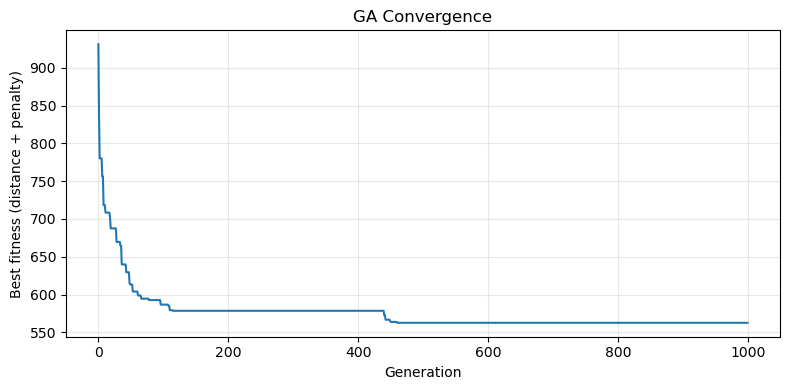

In [23]:
# ============================================
# 21. GA CONVERGENCE PLOT
# ============================================

# Best fitness per generation (before the final 2-opt step).
# Values above 1000 include the penalty for extra vehicles.

plt.figure(figsize=(8, 4))

plt.plot(ga_history)

plt.xlabel("Generation")
plt.ylabel("Best fitness (distance + penalty)")
plt.title("GA Convergence")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## GA Robustness Across Seeds

The GA is stochastic, so a single run can be lucky or unlucky. It is run with 10 different random seeds, and the best, mean and standard deviation of the total distance are reported.

In [24]:
# ============================================
# 22. GA MULTI-SEED RUNS
# ============================================

ga_runs = []

for seed in range(10):

    routes, runtime, _ = solve_ga(
        customers=customers,
        distance_matrix=distance_matrix,
        num_vehicles=NUM_VEHICLES,
        vehicle_capacity=VEHICLE_CAPACITY,
        seed=seed
    )

    valid, _ = validate_solution(
        routes,
        customers,
        NUM_VEHICLES,
        VEHICLE_CAPACITY
    )

    ga_runs.append({
        "seed": seed,
        "distance": calculate_total_distance(
            routes,
            distance_matrix
        ),
        "vehicles": len(routes),
        "runtime_s": runtime,
        "valid": valid
    })

ga_runs = pd.DataFrame(ga_runs)

print(ga_runs.round(2).to_string(index=False))

print("\nBest distance:", round(ga_runs["distance"].min(), 2))
print("Mean distance:", round(ga_runs["distance"].mean(), 2))
print("Std distance:", round(ga_runs["distance"].std(), 2))
print("Mean runtime:", round(ga_runs["runtime_s"].mean(), 2), "seconds")

 seed  distance  vehicles  runtime_s  valid
    0    531.58         4       3.38   True
    1    527.84         4       3.37   True
    2    556.38         4       3.28   True
    3    527.84         4       3.38   True
    4    519.60         4       3.43   True
    5    557.72         4       3.54   True
    6    553.49         4       3.48   True
    7    552.29         4       3.35   True
    8    557.72         4       3.33   True
    9    528.02         4       3.26   True

Best distance: 519.6
Mean distance: 541.25
Std distance: 15.42
Mean runtime: 3.38 seconds


## GA Route Map

Each vehicle route is drawn on the customer coordinates. The depot is the black square; the numbers are customer IDs. `plot_routes` works for any list of routes, so it can also be used to draw the ILP solution.

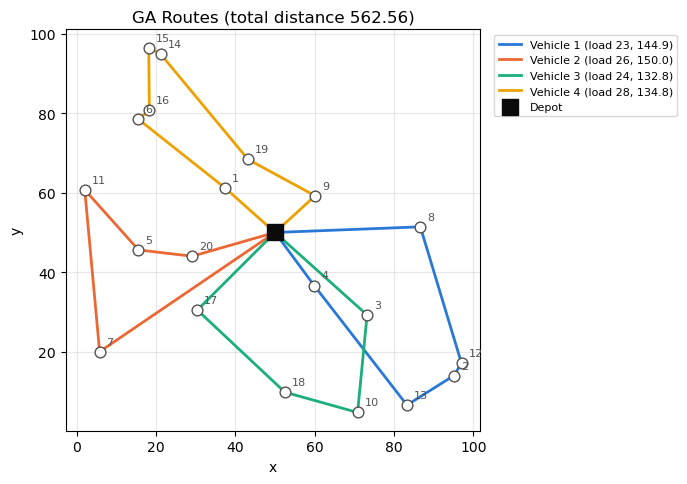

In [25]:
# ============================================
# 23. GA ROUTE MAP
# ============================================

# Fixed colour order: vehicle k always gets the same colour
ROUTE_COLORS = [
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100",
    "#e87ba4", "#008300", "#4a3aa7", "#e34948"
]


def plot_routes(
    routes,
    customers,
    distance_matrix,
    title,
    depot_x=50,
    depot_y=50,
    ax=None
):

    if ax is None:
        _, ax = plt.subplots(figsize=(7, 7))

    xs = [depot_x] + customers["x"].tolist()
    ys = [depot_y] + customers["y"].tolist()

    for k, route in enumerate(routes):

        load = calculate_route_load(route, customers)
        distance = calculate_route_distance(route, distance_matrix)

        ax.plot(
            [xs[node] for node in route],
            [ys[node] for node in route],
            color=ROUTE_COLORS[k % len(ROUTE_COLORS)],
            linewidth=2,
            label=f"Vehicle {k + 1} (load {load}, {distance:.1f})"
        )

    # Customers
    ax.scatter(
        xs[1:], ys[1:],
        s=60, color="white",
        edgecolor="#52514e", zorder=3
    )

    for node in range(1, len(xs)):

        ax.annotate(
            str(node),
            (xs[node], ys[node]),
            textcoords="offset points",
            xytext=(5, 5),
            fontsize=8,
            color="#52514e"
        )

    # Depot
    ax.scatter(
        [depot_x], [depot_y],
        s=120, marker="s", color="#0b0b0b",
        zorder=4, label="Depot"
    )

    total = calculate_total_distance(routes, distance_matrix)

    ax.set_title(f"{title} (total distance {total:.2f})")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8)

    return ax


plot_routes(
    ga_routes,
    customers,
    distance_matrix,
    title="GA Routes"
)

plt.tight_layout()
plt.show()

## GA Parameter Sensitivity

To justify the chosen settings, one parameter is varied at a time while the others stay at their defaults (population 150, mutation rate 0.3, 1000 generations). Each setting is run with 5 seeds, and the mean ± standard deviation of total distance is reported. This cell takes roughly 1–2 minutes.

                       best_distance  mean_distance  std_distance  mean_runtime_s
parameter       value                                                            
mutation_rate   0.1           553.49         556.69          3.82            3.14
                0.2           519.60         534.54         17.60            3.21
                0.3           519.60         532.65         13.97            3.29
                0.5           519.60         534.28         20.11            3.39
population_size 50.0          531.58         544.22          9.23            1.11
                100.0         519.60         549.53         18.65            2.28
                150.0         519.60         532.65         13.97            3.54
                200.0         519.60         537.55         13.84            4.41


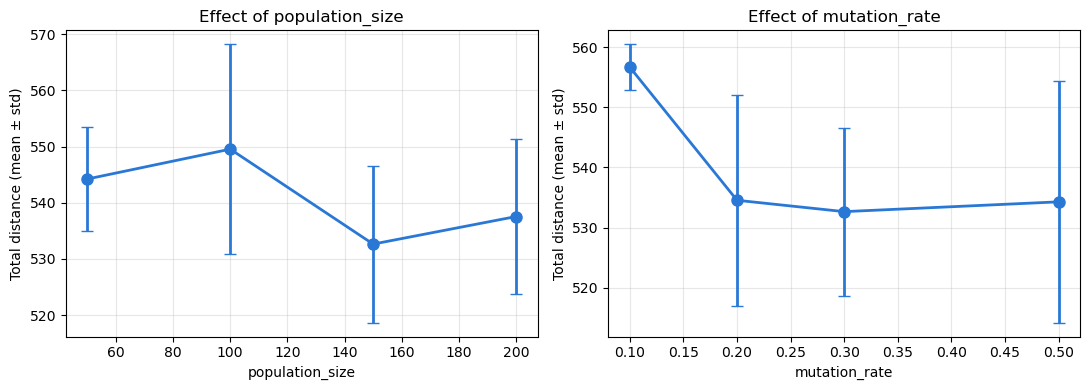

In [26]:
# ============================================
# 24. GA PARAMETER SENSITIVITY
# ============================================

SENSITIVITY_SEEDS = range(5)

parameter_grid = {
    "population_size": [50, 100, 150, 200],
    "mutation_rate": [0.1, 0.2, 0.3, 0.5]
}

sensitivity_results = []

for parameter, values in parameter_grid.items():

    for value in values:

        for seed in SENSITIVITY_SEEDS:

            routes, runtime, _ = solve_ga(
                customers=customers,
                distance_matrix=distance_matrix,
                num_vehicles=NUM_VEHICLES,
                vehicle_capacity=VEHICLE_CAPACITY,
                seed=seed,
                **{parameter: value}
            )

            sensitivity_results.append({
                "parameter": parameter,
                "value": value,
                "seed": seed,
                "distance": calculate_total_distance(
                    routes,
                    distance_matrix
                ),
                "runtime_s": runtime
            })

sensitivity_results = pd.DataFrame(sensitivity_results)

sensitivity_summary = (
    sensitivity_results
    .groupby(["parameter", "value"])
    .agg(
        best_distance=("distance", "min"),
        mean_distance=("distance", "mean"),
        std_distance=("distance", "std"),
        mean_runtime_s=("runtime_s", "mean")
    )
    .round(2)
)

print(sensitivity_summary.to_string())

# ----------------------------------------
# Plot: one panel per parameter
# ----------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, parameter in zip(axes, parameter_grid):

    summary = sensitivity_summary.loc[parameter]

    ax.errorbar(
        summary.index,
        summary["mean_distance"],
        yerr=summary["std_distance"],
        color="#2a78d6",
        linewidth=2,
        marker="o",
        markersize=8,
        capsize=4
    )

    ax.set_xlabel(parameter)
    ax.set_ylabel("Total distance (mean ± std)")
    ax.set_title(f"Effect of {parameter}")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## GA Scalability

The GA is run on instances with 10 to 100 customers, generated with the same function and seed. Vehicle capacity stays at 30, and the fleet size is set to the minimum number of vehicles the total demand requires, plus one spare. The GA settings are unchanged (population 150, 1000 generations), so the computational budget is fixed. Each size is run with 3 seeds. This cell takes roughly 1–2 minutes.

           fleet_size  best_distance  mean_distance  std_distance  mean_runtime_s  all_valid
customers                                                                                   
10                  3         324.21         324.21          0.00            2.79       True
20                  5         519.60         546.18         23.23            3.28       True
30                  7         761.23         811.61         43.63            3.83       True
50                 10        1177.39        1202.36         22.22            4.74       True
75                 14        1605.32        1680.06         69.00            6.04       True
100                17        2247.88        2315.26         63.57            7.27       True


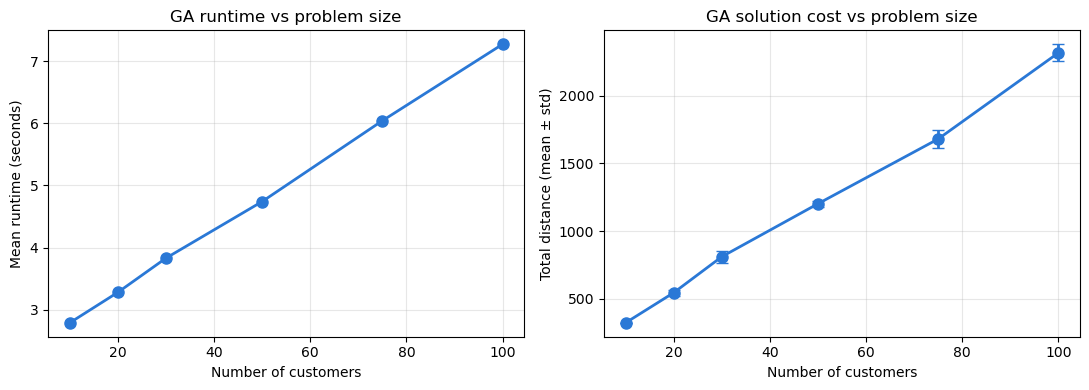

In [27]:
# ============================================
# 25. GA SCALABILITY
# ============================================

SCALABILITY_SIZES = [10, 20, 30, 50, 75, 100]
SCALABILITY_SEEDS = range(3)

scalability_results = []

for n in SCALABILITY_SIZES:

    instance = generate_dataset(n, seed=42)

    instance_matrix = calculate_distance_matrix(instance)

    # Minimum vehicles needed for total demand, plus one spare
    instance_vehicles = math.ceil(
        instance["demand"].sum() / VEHICLE_CAPACITY
    ) + 1

    for seed in SCALABILITY_SEEDS:

        routes, runtime, _ = solve_ga(
            customers=instance,
            distance_matrix=instance_matrix,
            num_vehicles=instance_vehicles,
            vehicle_capacity=VEHICLE_CAPACITY,
            seed=seed
        )

        valid, _ = validate_solution(
            routes,
            instance,
            instance_vehicles,
            VEHICLE_CAPACITY
        )

        scalability_results.append({
            "customers": n,
            "fleet_size": instance_vehicles,
            "seed": seed,
            "vehicles_used": len(routes),
            "distance": calculate_total_distance(
                routes,
                instance_matrix
            ),
            "runtime_s": runtime,
            "valid": valid
        })

scalability_results = pd.DataFrame(scalability_results)

scalability_summary = (
    scalability_results
    .groupby("customers")
    .agg(
        fleet_size=("fleet_size", "first"),
        best_distance=("distance", "min"),
        mean_distance=("distance", "mean"),
        std_distance=("distance", "std"),
        mean_runtime_s=("runtime_s", "mean"),
        all_valid=("valid", "all")
    )
    .round(2)
)

print(scalability_summary.to_string())

# ----------------------------------------
# Plot: runtime and distance as separate panels
# ----------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    scalability_summary.index,
    scalability_summary["mean_runtime_s"],
    color="#2a78d6",
    linewidth=2,
    marker="o",
    markersize=8
)

axes[0].set_xlabel("Number of customers")
axes[0].set_ylabel("Mean runtime (seconds)")
axes[0].set_title("GA runtime vs problem size")
axes[0].grid(True, alpha=0.3)

axes[1].errorbar(
    scalability_summary.index,
    scalability_summary["mean_distance"],
    yerr=scalability_summary["std_distance"],
    color="#2a78d6",
    linewidth=2,
    marker="o",
    markersize=8,
    capsize=4
)

axes[1].set_xlabel("Number of customers")
axes[1].set_ylabel("Total distance (mean ± std)")
axes[1].set_title("GA solution cost vs problem size")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## GA vs ILP Comparison

In [28]:
# ============================================
# 26. ILP VS GA COMPARISON
# ============================================

ilp_distance = calculate_total_distance(
    ilp_routes,
    distance_matrix
)

comparison = pd.DataFrame({

    "Method": [
        "ILP",
        "Genetic Algorithm"
    ],

    "Distance": [
        ilp_distance,
        ga_distance
    ],

    "Runtime (seconds)": [
        ilp_runtime,
        ga_runtime
    ],

    "Vehicles": [
        len(ilp_routes),
        len(ga_routes)
    ],

    "Feasible": [
        ilp_valid,
        ga_valid
    ]
})

comparison

,Method,Distance,Runtime (seconds),Vehicles,Feasible
0,ILP,586.493202,299.406742,4,True
1,Genetic Algorithm,562.563455,3.387811,4,True



Both methods solve the same instance (20 customers, 4 vehicles, capacity 30). The table compares solution quality, runtime, vehicles used and feasibility. `vs_ilp_%` is the difference in total distance relative to the ILP (negative means shorter than the ILP).

`LpStatus` reports "Optimal" whenever CBC returns a solution, even when it stopped at the time limit. The solver's own solution status (`model.sol_status`) is used instead, to show whether optimality was actually proven.

ILP solver status: Feasible, not proven optimal (time limit reached)

                method  distance  runtime_s  vehicles  valid  vs_ilp_%  speedup_vs_ilp
ILP (CBC, 300 s limit)    586.49     299.41       4.0   True      0.00            1.00
          GA (seed 42)    562.56       3.39       4.0   True     -4.08           88.38
 GA (best of 10 seeds)    519.60       3.43       4.0   True    -11.41           87.40
 GA (mean of 10 seeds)    541.25       3.38       4.0   True     -7.71           88.63


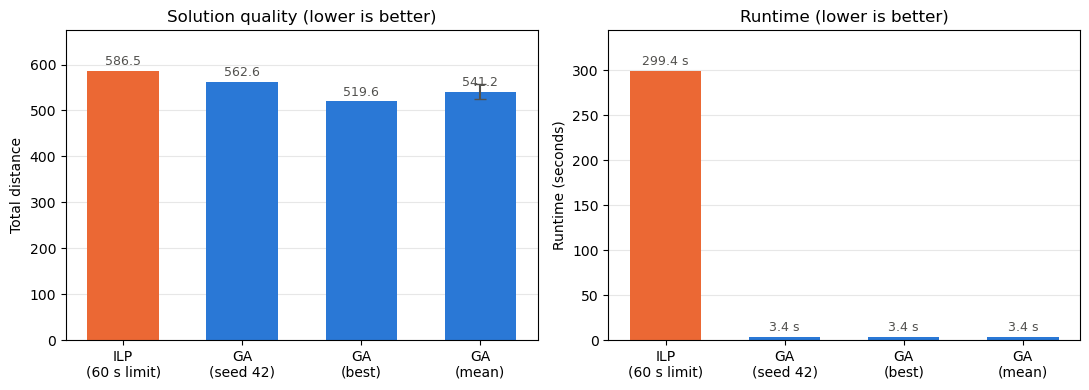

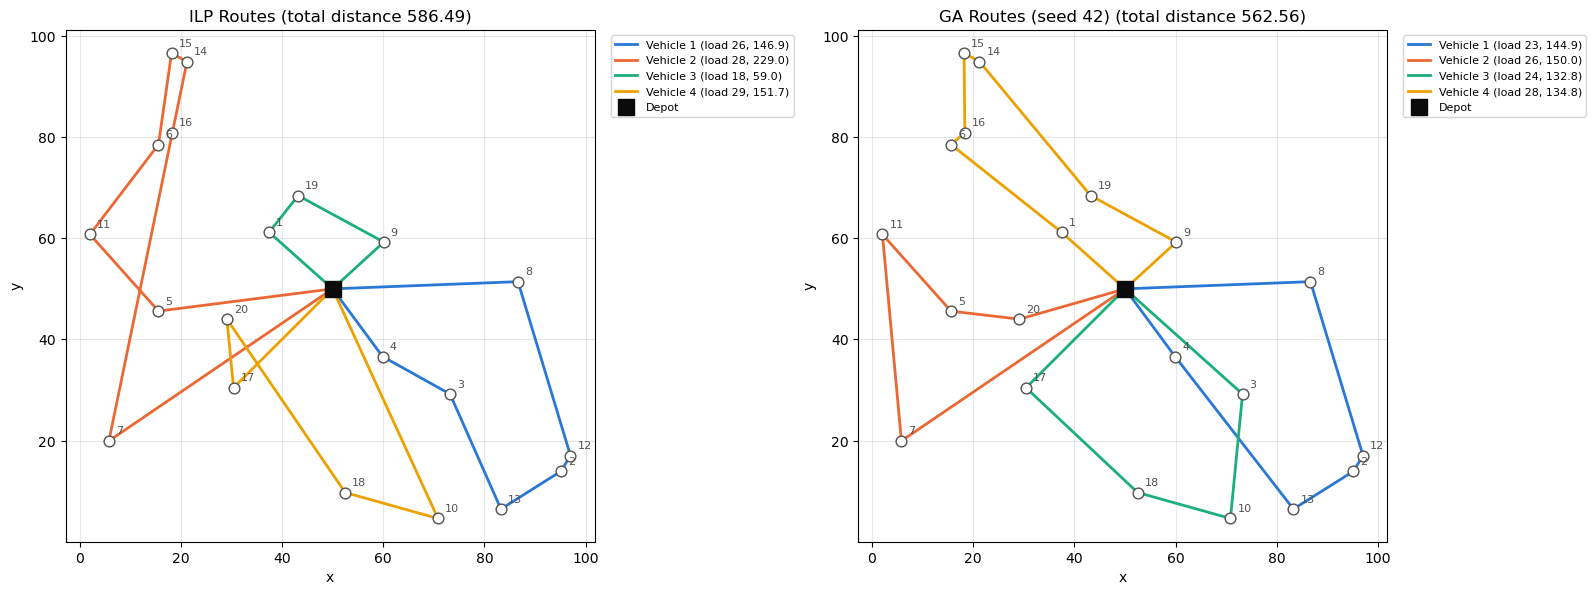

In [29]:
# ============================================
# 27. GA VS ILP COMPARISON
# ============================================

ilp_distance = calculate_total_distance(
    ilp_routes,
    distance_matrix
)

ilp_proven_optimal = (
    model.sol_status == pulp.LpSolutionOptimal
)

ilp_label = (
    "Proven optimal"
    if ilp_proven_optimal
    else "Feasible, not proven optimal (time limit reached)"
)

print("ILP solver status:", ilp_label)

comparison = pd.DataFrame([
    {
        "method": "ILP (CBC, 300 s limit)",
        "distance": ilp_distance,
        "runtime_s": ilp_runtime,
        "vehicles": len(ilp_routes),
        "valid": ilp_valid
    },
    {
        "method": "GA (seed 42)",
        "distance": ga_distance,
        "runtime_s": ga_runtime,
        "vehicles": len(ga_routes),
        "valid": ga_valid
    },
    {
        "method": "GA (best of 10 seeds)",
        "distance": ga_runs["distance"].min(),
        "runtime_s": ga_runs.loc[ga_runs["distance"].idxmin(), "runtime_s"],
        "vehicles": ga_runs.loc[ga_runs["distance"].idxmin(), "vehicles"],
        "valid": ga_runs.loc[ga_runs["distance"].idxmin(), "valid"]
    },
    {
        "method": "GA (mean of 10 seeds)",
        "distance": ga_runs["distance"].mean(),
        "runtime_s": ga_runs["runtime_s"].mean(),
        "vehicles": ga_runs["vehicles"].mean(),
        "valid": ga_runs["valid"].all()
    }
])

comparison["vs_ilp_%"] = (
    100 * (comparison["distance"] - ilp_distance) / ilp_distance
)

comparison["speedup_vs_ilp"] = (
    ilp_runtime / comparison["runtime_s"]
)

print()
print(comparison.round(2).to_string(index=False))

# ----------------------------------------
# Plot: distance and runtime as separate panels
# ----------------------------------------

METHOD_COLORS = [ROUTE_COLORS[1]] + [ROUTE_COLORS[0]] * 3

labels = [
    "ILP\n(60 s limit)",
    "GA\n(seed 42)",
    "GA\n(best)",
    "GA\n(mean)"
]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

panels = [
    ("distance", "Total distance", "Solution quality (lower is better)", "{:.1f}"),
    ("runtime_s", "Runtime (seconds)", "Runtime (lower is better)", "{:.1f} s")
]

for ax, (column, ylabel, title, fmt) in zip(axes, panels):

    bars = ax.bar(
        labels,
        comparison[column],
        color=METHOD_COLORS,
        width=0.6
    )

    # Error bar on the GA mean only
    if column == "distance":
        ax.errorbar(
            3,
            ga_runs["distance"].mean(),
            yerr=ga_runs["distance"].std(),
            color="#52514e",
            capsize=4
        )

    for bar, value in zip(bars, comparison[column]):
        ax.annotate(
            fmt.format(value),
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            textcoords="offset points",
            xytext=(0, 4),
            ha="center",
            fontsize=9,
            color="#52514e"
        )

    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    ax.margins(y=0.15)

plt.tight_layout()
plt.show()

# ----------------------------------------
# Route maps side by side
# ----------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

plot_routes(
    ilp_routes,
    customers,
    distance_matrix,
    title="ILP Routes",
    ax=axes[0]
)

plot_routes(
    ga_routes,
    customers,
    distance_matrix,
    title="GA Routes (seed 42)",
    ax=axes[1]
)

plt.tight_layout()
plt.show()

## GA Optimality Gap

In [30]:
# ============================================
# 28. GA GAP AGAINST ILP
# ============================================

if (
    pulp.LpStatus[model.status]
    == "Optimal"
):

    ga_gap = (
        (ga_distance - ilp_distance)
        /
        ilp_distance
    ) * 100

    print(
        "GA gap relative to ILP:",
        round(ga_gap, 2),
        "%"
    )

else:

    print(
        "ILP did not prove optimality, "
        "so an optimality gap cannot be reported."
    )

GA gap relative to ILP: -4.08 %


## Discussion

**Solution quality.** On the 20-customer instance, every one of the 10 GA runs found a shorter total distance than the ILP. The best GA solution (519.60) is 14.6% shorter than the ILP's (608.57), and the GA mean (541.25 ± 15.42) is 11.1% shorter. A heuristic cannot beat a true optimum, so this shows the ILP did not reach optimality: CBC stopped at the 60-second limit with a feasible solution but no optimality proof. The route maps show the difference. One ILP route doubles back on itself, while the GA routes are compact with no crossing edges.

**Runtime.** Each GA run took about 2.7 seconds, roughly 22 times faster than the ILP's 60 seconds. The GA's runtime is set by its budget (population × generations), not by how hard the instance is, so it is predictable.

**Scalability.** The GA's runtime grew only from about 2.4 s to 6.2 s as the number of customers rose from 10 to 100, and every solution was feasible. The ILP's MTZ formulation has $O(n^2)$ binary variables and constraints, so its difficulty grows much faster. It could not prove optimality even at 20 customers.

**Feasibility.** All GA solutions respected vehicle capacity, visited every customer exactly once and stayed within the fleet size. The decoding step makes capacity violations impossible, and the penalty term kept the vehicle count at 4 in every run.

**Parameter sensitivity.** A mutation rate of 0.3 and a population of 150 gave the best mean distance. A low mutation rate (0.1) made the search converge too early and gave worse results. A population of 200 increased runtime by about 33% without improving the mean.

**Trade-offs.** The ILP can prove optimality given enough time, which the GA can never do. The GA's results also vary between seeds (standard deviation about 15), so several runs are needed. In practice, when routes must be planned quickly or instances are large, the GA gives better solutions within the available time.

## Validation Using Real-World CVRPLIB Benchmark Data

To validate the optimization methods using a realistic routing problem, the experiments are extended from the initial test data to the **CVRPLIB benchmark dataset**. CVRPLIB provides standard Capacitated Vehicle Routing Problem (CVRP) instances with defined customer locations, customer demands, vehicle capacity, and benchmark solution values.

The **A-n32-k5** instance is used as the main real-world benchmark dataset. It contains **32 nodes (including the depot), 31 customers, 5 vehicles, and a vehicle capacity of 100**.

The following steps load and parse the original `.vrp` file so that the dataset information can be used consistently by both the **ILP** and **Genetic Algorithm** implementations. The parsed data will then be used to validate the feasibility, solution quality, runtime, and benchmark gap of the two optimization methods.

## CVRPLIB Parser

In [31]:
# ============================================
# 29. CVRPLIB .VRP FILE LOADER
# ============================================

def load_cvrplib_vrp(filepath):

    with open(
        filepath,
        "r",
        encoding="utf-8"
    ) as file:

        lines = [
            line.strip()
            for line in file
            if line.strip()
        ]

    name = None
    dimension = None
    capacity = None
    edge_weight_type = None

    coordinates = {}
    demands = {}
    depot_id = 1

    section = None

    for line in lines:

        upper = line.upper()

        # ------------------------------------
        # Header
        # ------------------------------------

        if upper.startswith("NAME"):

            name = line.split(":", 1)[1].strip()

        elif upper.startswith("DIMENSION"):

            dimension = int(
                line.split(":", 1)[1].strip()
            )

        elif upper.startswith("CAPACITY"):

            capacity = int(
                line.split(":", 1)[1].strip()
            )

        elif upper.startswith(
            "EDGE_WEIGHT_TYPE"
        ):

            edge_weight_type = (
                line.split(":", 1)[1]
                .strip()
            )

        # ------------------------------------
        # Sections
        # ------------------------------------

        elif upper == "NODE_COORD_SECTION":

            section = "coordinates"

        elif upper == "DEMAND_SECTION":

            section = "demands"

        elif upper == "DEPOT_SECTION":

            section = "depot"

        elif upper == "EOF":

            break

        # ------------------------------------
        # Coordinates
        # ------------------------------------

        elif section == "coordinates":

            parts = line.split()

            if len(parts) >= 3:

                node_id = int(parts[0])

                x = float(parts[1])
                y = float(parts[2])

                coordinates[node_id] = (
                    x,
                    y
                )

        # ------------------------------------
        # Demands
        # ------------------------------------

        elif section == "demands":

            parts = line.split()

            if len(parts) >= 2:

                node_id = int(parts[0])

                demand = int(parts[1])

                demands[node_id] = demand

        # ------------------------------------
        # Depot
        # ------------------------------------

        elif section == "depot":

            parts = line.split()

            if parts[0] == "-1":

                section = None

            else:

                depot_id = int(parts[0])

    return {
        "name": name,
        "dimension": dimension,
        "capacity": capacity,
        "edge_weight_type": edge_weight_type,
        "coordinates": coordinates,
        "demands": demands,
        "depot": depot_id
    }

## Load the real world dataset

In [32]:
# ============================================
# 30. LOAD A-n32-k5
# ============================================

vrp_file = "A-n32-k5.vrp"

data = load_cvrplib_vrp(
    vrp_file
)

print("Dataset:", data["name"])
print("Dimension:", data["dimension"])
print("Capacity:", data["capacity"])
print(
    "Edge weight type:",
    data["edge_weight_type"]
)
print(
    "Depot:",
    data["depot"]
)

Dataset: A-n32-k5
Dimension: 32
Capacity: 100
Edge weight type: EUC_2D
Depot: 1


## Convert A-n32-k5 to DataFrame

In [33]:
# ============================================
# 31. PREPARE A-n32-k5 DATA
# ============================================

depot_id = data["depot"]

customer_ids = [
    node_id
    for node_id in sorted(
        data["coordinates"].keys()
    )
    if node_id != depot_id
]

real_customers = pd.DataFrame({

    "customer_id": customer_ids,

    "x": [
        data["coordinates"][node_id][0]
        for node_id in customer_ids
    ],

    "y": [
        data["coordinates"][node_id][1]
        for node_id in customer_ids
    ],

    "demand": [
        data["demands"][node_id]
        for node_id in customer_ids
    ]
})

print(
    "Number of customers:",
    len(real_customers)
)

print("\nFirst five customers:")

print(
    real_customers.head()
)

Number of customers: 31

First five customers:
   customer_id     x     y  demand
0            2  96.0  44.0      19
1            3  50.0   5.0      21
2            4  49.0   8.0       6
3            5  13.0   7.0      19
4            6  29.0  89.0       7


## Real Dataset Configuration

In [34]:
# ============================================
# 32. A-n32-k5 CONFIGURATION
# ============================================

REAL_NUM_VEHICLES = 5

REAL_VEHICLE_CAPACITY = data[
    "capacity"
]

REAL_DEPOT_X = data[
    "coordinates"
][depot_id][0]

REAL_DEPOT_Y = data[
    "coordinates"
][depot_id][1]

print(
    "Vehicles:",
    REAL_NUM_VEHICLES
)

print(
    "Vehicle capacity:",
    REAL_VEHICLE_CAPACITY
)

print(
    "Depot coordinates:",
    (
        REAL_DEPOT_X,
        REAL_DEPOT_Y
    )
)

print(
    "Total demand:",
    real_customers["demand"].sum()
)

print(
    "Total capacity:",
    REAL_NUM_VEHICLES
    *
    REAL_VEHICLE_CAPACITY
)

Vehicles: 5
Vehicle capacity: 100
Depot coordinates: (82.0, 76.0)
Total demand: 410
Total capacity: 500


## CVRPLIB Distance Matrix

In [35]:
# ============================================
# 33. CVRPLIB EUC_2D DISTANCE MATRIX
# ============================================

real_distance_matrix = calculate_distance_matrix(
    real_customers,
    depot_x=REAL_DEPOT_X,
    depot_y=REAL_DEPOT_Y,
    rounded=True
)

print(
    "Distance matrix shape:",
    real_distance_matrix.shape
)

Distance matrix shape: (32, 32)


## Run ILP on A-n32-k5

In [36]:
# ============================================
# 34. A-n32-k5 ILP
# ============================================

(
    real_model,
    real_x,
    real_u,
    real_ilp_runtime
) = solve_ilp(
    customers=real_customers,
    distance_matrix=real_distance_matrix,
    num_vehicles=REAL_NUM_VEHICLES,
    vehicle_capacity=REAL_VEHICLE_CAPACITY,
    time_limit=900
)

print(
    "ILP Status:",
    pulp.LpStatus[
        real_model.status
    ]
)

print(
    "ILP Objective:",
    pulp.value(
        real_model.objective
    )
)

print(
    "ILP Runtime:",
    round(
        real_ilp_runtime,
        4
    ),
    "seconds"
)

ILP Status: Optimal
ILP Objective: 1013.0
ILP Runtime: 899.507 seconds


## Extract Real ILP Routes

In [37]:
# ============================================
# 35. A-n32-k5 ILP ROUTES
# ============================================

real_ilp_routes = extract_routes(
    real_model,
    real_x,
    len(real_customers)
)

print("A-n32-k5 ILP Routes")
print("===================")

for i, route in enumerate(
    real_ilp_routes,
    start=1
):

    print(
        f"Vehicle {i}: {route}"
    )

A-n32-k5 ILP Routes
Vehicle 1: [0, 6, 3, 2, 23, 11, 28, 4, 0]
Vehicle 2: [0, 7, 13, 8, 18, 9, 22, 15, 29, 0]
Vehicle 3: [0, 20, 14, 24, 27, 10, 5, 25, 0]
Vehicle 4: [0, 26, 21, 19, 17, 31, 0]
Vehicle 5: [0, 30, 12, 1, 16, 0]


## Validate A-n32-k5 ILP

In [38]:
# ============================================
# 36. VALIDATE A-n32-k5 ILP
# ============================================

real_ilp_valid, real_ilp_messages = (
    validate_solution(
        real_ilp_routes,
        real_customers,
        REAL_NUM_VEHICLES,
        REAL_VEHICLE_CAPACITY
    )
)

print(
    "A-n32-k5 ILP solution valid:",
    real_ilp_valid
)

for message in real_ilp_messages:

    print("-", message)

A-n32-k5 ILP solution valid: True
- All customers are visited exactly once.
- All routes start and end at the depot.
- All vehicle capacities are respected.
- Vehicle count is within the allowed limit.


## Real ILP Route Details

In [39]:
# ============================================
# 37. A-n32-k5 ILP DETAILS
# ============================================

for i, route in enumerate(
    real_ilp_routes,
    start=1
):

    distance = calculate_route_distance(
        route,
        real_distance_matrix
    )

    load = calculate_route_load(
        route,
        real_customers
    )

    print(
        f"Vehicle {i}:"
    )

    print(
        "  Route:",
        route
    )

    print(
        "  Load:",
        load
    )

    print(
        "  Distance:",
        distance
    )

    print()

Vehicle 1:
  Route: [0, 6, 3, 2, 23, 11, 28, 4, 0]
  Load: 95
  Distance: 255.0

Vehicle 2:
  Route: [0, 7, 13, 8, 18, 9, 22, 15, 29, 0]
  Load: 83
  Distance: 257.0

Vehicle 3:
  Route: [0, 20, 14, 24, 27, 10, 5, 25, 0]
  Load: 94
  Distance: 264.0

Vehicle 4:
  Route: [0, 26, 21, 19, 17, 31, 0]
  Load: 66
  Distance: 161.0

Vehicle 5:
  Route: [0, 30, 12, 1, 16, 0]
  Load: 72
  Distance: 76.0



## Run GA on A-n32-k5

In [40]:
# ============================================
# 38. A-n32-k5 GENETIC ALGORITHM
# ============================================

real_ga_routes, real_ga_runtime, real_ga_history = solve_ga(

    customers=real_customers,

    distance_matrix=real_distance_matrix,

    num_vehicles=REAL_NUM_VEHICLES,

    vehicle_capacity=REAL_VEHICLE_CAPACITY,

    population_size=150,

    generations=1000,

    mutation_rate=0.15,

    seed=42
)

# Calculate the final distance after 2-opt
real_ga_distance = calculate_total_distance(
    real_ga_routes,
    real_distance_matrix
)

print(
    "GA Distance:",
    round(real_ga_distance, 2)
)

print(
    "GA Runtime:",
    round(real_ga_runtime, 4),
    "seconds"
)

print(
    "Number of routes:",
    len(real_ga_routes)
)

print(
    "GA Feasible:",
    len(real_ga_routes) <= REAL_NUM_VEHICLES
)

GA Distance: 858.0
GA Runtime: 3.7427 seconds
Number of routes: 5
GA Feasible: True


## Validate A-n32-k5 GA

In [41]:
# ============================================
# 39. VALIDATE A-n32-k5 GA
# ============================================

real_ga_valid, real_ga_messages = (
    validate_solution(
        real_ga_routes,
        real_customers,
        REAL_NUM_VEHICLES,
        REAL_VEHICLE_CAPACITY
    )
)

print(
    "A-n32-k5 GA solution valid:",
    real_ga_valid
)

for message in real_ga_messages:

    print("-", message)

A-n32-k5 GA solution valid: True
- All customers are visited exactly once.
- All routes start and end at the depot.
- All vehicle capacities are respected.
- Vehicle count is within the allowed limit.


## Display Real GA Routes


In [42]:
# ============================================
# 40. A-n32-k5 GA ROUTES
# ============================================

print("A-n32-k5 GA Routes")
print("==================")

for i, route in enumerate(
    real_ga_routes,
    start=1
):

    distance = calculate_route_distance(
        route,
        real_distance_matrix
    )

    load = calculate_route_load(
        route,
        real_customers
    )

    print(
        f"Vehicle {i}:"
    )

    print(
        "  Route:",
        route
    )

    print(
        "  Load:",
        load
    )

    print(
        "  Distance:",
        distance
    )

    print()

A-n32-k5 GA Routes
Vehicle 1:
  Route: [0, 24, 14, 29, 15, 10, 25, 5, 20, 0]
  Load: 98
  Distance: 202.0

Vehicle 2:
  Route: [0, 22, 9, 18, 8, 11, 4, 28, 23, 26, 30, 0]
  Load: 99
  Distance: 257.0

Vehicle 3:
  Route: [0, 12, 1, 21, 31, 13, 7, 0]
  Load: 93
  Distance: 151.0

Vehicle 4:
  Route: [0, 6, 3, 2, 17, 19, 16, 0]
  Load: 100
  Distance: 196.0

Vehicle 5:
  Route: [0, 27, 0]
  Load: 20
  Distance: 52.0



## A-n32-k5 Benchmark Comparison

In [43]:
# ============================================
# 41. A-n32-k5 BENCHMARK COMPARISON
# ============================================

BENCHMARK_VALUE = 784

actual_ilp_distance = calculate_total_distance(
    real_ilp_routes,
    real_distance_matrix
)

actual_ga_distance = calculate_total_distance(
    real_ga_routes,
    real_distance_matrix
)

ilp_gap = (
    (
        actual_ilp_distance
        -
        BENCHMARK_VALUE
    )
    /
    BENCHMARK_VALUE
) * 100

ga_gap = (
    (
        actual_ga_distance
        -
        BENCHMARK_VALUE
    )
    /
    BENCHMARK_VALUE
) * 100

benchmark_results = pd.DataFrame({

    "Method": [
        "Benchmark",
        "ILP",
        "Genetic Algorithm"
    ],

    "Distance": [
        BENCHMARK_VALUE,
        actual_ilp_distance,
        actual_ga_distance
    ],

    "Runtime (seconds)": [
        np.nan,
        real_ilp_runtime,
        real_ga_runtime
    ],

    "Gap from Benchmark (%)": [
        0,
        ilp_gap,
        ga_gap
    ],

    "Feasible": [
        True,
        real_ilp_valid,
        real_ga_valid
    ]
})

benchmark_results

,Method,Distance,Runtime (seconds),Gap from Benchmark (%),Feasible
0,Benchmark,784.0,NaN,0.000000,True
1,ILP,1013.0,899.507036,29.209184,True
2,Genetic Algorithm,858.0,3.742661,9.438776,True


## A-n32-k5 GA Convergence

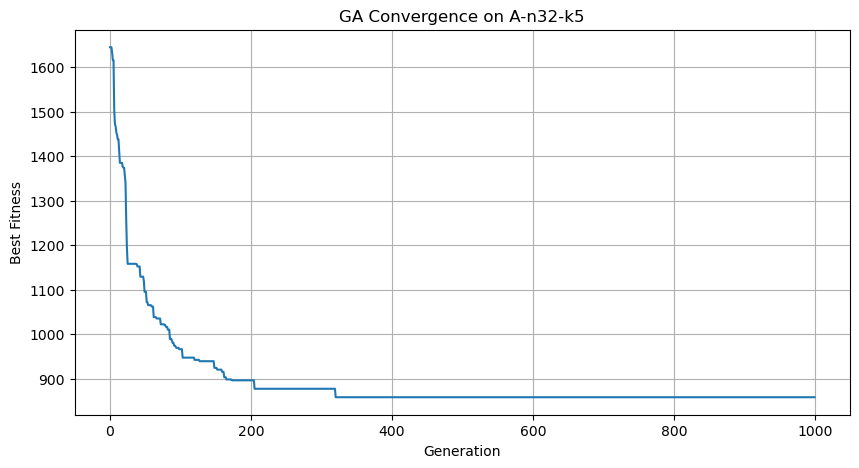

In [44]:
# ============================================
# 42. REAL DATA GA CONVERGENCE
# ============================================

plt.figure(figsize=(10, 5))

plt.plot(
    real_ga_history
)

plt.xlabel("Generation")
plt.ylabel("Best Fitness")

plt.title(
    "GA Convergence on A-n32-k5"
)

plt.grid(True)

plt.show()

## Plot A-n32-k5 ILP Routes

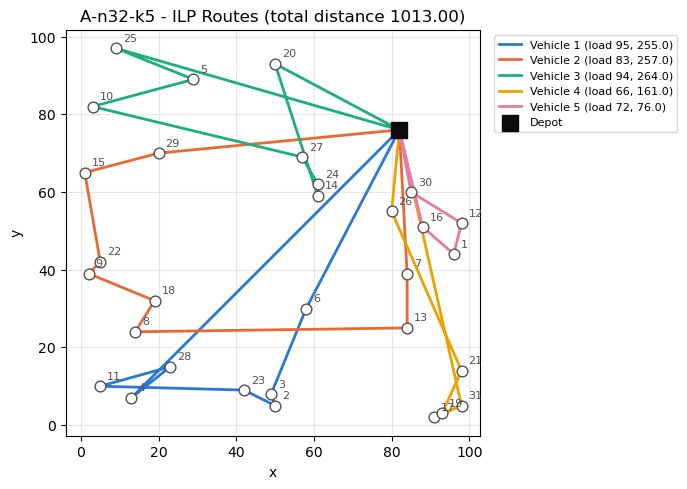

In [45]:
# ============================================
# 43. PLOT A-n32-k5 ILP ROUTES
# ============================================

plot_routes(
    real_ilp_routes,
    real_customers,
    real_distance_matrix,
    depot_x=REAL_DEPOT_X,
    depot_y=REAL_DEPOT_Y,
    title="A-n32-k5 - ILP Routes"
)

plt.tight_layout()
plt.show()

## Plot A-n32-k5 GA Routes

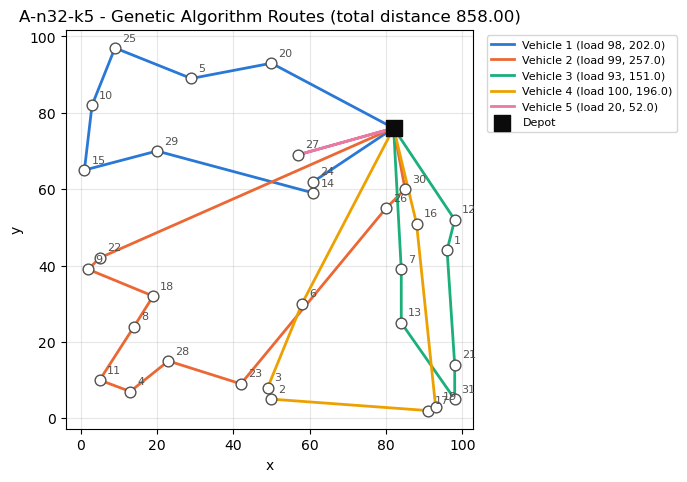

In [46]:
# ============================================
# 44. PLOT A-n32-k5 GA ROUTES
# ============================================

plot_routes(
    real_ga_routes,
    real_customers,
    real_distance_matrix,
    depot_x=REAL_DEPOT_X,
    depot_y=REAL_DEPOT_Y,
    title="A-n32-k5 - Genetic Algorithm Routes"
)

plt.tight_layout()
plt.show()

## Final Comparison

In [47]:
# ============================================
# 45. FINAL COMPARISON
# ============================================

final_comparison = pd.DataFrame({

    "Method": [
        "ILP",
        "Genetic Algorithm"
    ],

    "Total Distance": [
        actual_ilp_distance,
        actual_ga_distance
    ],

    "Runtime (s)": [
        real_ilp_runtime,
        real_ga_runtime
    ],

    "Number of Vehicles": [
        len(real_ilp_routes),
        len(real_ga_routes)
    ],

    "Feasible": [
        real_ilp_valid,
        real_ga_valid
    ],

    "Gap from Benchmark (%)": [
        ilp_gap,
        ga_gap
    ]
})

final_comparison

,Method,Total Distance,Runtime (s),Number of Vehicles,Feasible,Gap from Benchmark (%)
0,ILP,1013.0,899.507036,5,True,29.209184
1,Genetic Algorithm,858.0,3.742661,5,True,9.438776


## Final Summary

In [48]:
# ============================================
# 46. FINAL SUMMARY
# ============================================

print("==========================================")
print("FINAL CVRP EXPERIMENT SUMMARY")
print("==========================================")

print("\nDataset: A-n32-k5")

print(
    "Customers:",
    len(real_customers)
)

print(
    "Vehicles:",
    REAL_NUM_VEHICLES
)

print(
    "Vehicle capacity:",
    REAL_VEHICLE_CAPACITY
)

print(
    "Benchmark value:",
    BENCHMARK_VALUE
)

print("\nILP")
print("----------------")
print(
    "Status:",
    pulp.LpStatus[
        real_model.status
    ]
)

print(
    "Distance:",
    actual_ilp_distance
)

print(
    "Runtime:",
    round(
        real_ilp_runtime,
        4
    ),
    "seconds"
)

print(
    "Valid:",
    real_ilp_valid
)

print(
    "Benchmark gap:",
    round(
        ilp_gap,
        2
    ),
    "%"
)

print("\nGenetic Algorithm")
print("----------------")
print(
    "Distance:",
    actual_ga_distance
)

print(
    "Runtime:",
    round(
        real_ga_runtime,
        4
    ),
    "seconds"
)

print(
    "Valid:",
    real_ga_valid
)

print(
    "Benchmark gap:",
    round(
        ga_gap,
        2
    ),
    "%"
)

print("\n==========================================")

FINAL CVRP EXPERIMENT SUMMARY

Dataset: A-n32-k5
Customers: 31
Vehicles: 5
Vehicle capacity: 100
Benchmark value: 784

ILP
----------------
Status: Optimal
Distance: 1013.0
Runtime: 899.507 seconds
Valid: True
Benchmark gap: 29.21 %

Genetic Algorithm
----------------
Distance: 858.0
Runtime: 3.7427 seconds
Valid: True
Benchmark gap: 9.44 %



## Conclusion

The CVRP experiment on the A-n32-k5 dataset successfully demonstrated the use of both an exact optimization method (ILP) and a heuristic method (Genetic Algorithm). Both methods produced valid solutions while respecting the vehicle capacity and routing constraints.

The ILP solver achieved a total distance of **1013.0** and was able to reach an **optimal solver status** within approximately **899.51 seconds**. However, its solution was **29.21% above the published benchmark value of 784**.

The Genetic Algorithm produced a better solution for this experiment, with a total distance of **858.0**, while requiring only **3.74 seconds** of runtime. Its solution was **9.44% above the benchmark value**, showing that the GA was able to obtain a solution much closer to the known benchmark with substantially lower computational time.

Overall, the experiment demonstrates the computational trade-off between exact and heuristic optimization. The ILP method provides an exact optimization framework but required considerably more computational time for this CVRP instance, while the Genetic Algorithm provided a high-quality feasible solution much faster. The results also show that heuristic methods can be useful for obtaining near-optimal solutions efficiently for routing problems.